# Observe vessels, preserve uncertainty

**Terrain & Earth observation · 15–25 minutes · learning companion**

Ocean Watch connects historical Global Fishing Watch (GFW) study products, radar, environmental evidence and One Health questions across nine source lessons. GFW maps vessel activity from several data sources. The Automatic Identification System (AIS) broadcasts vessel-reported identity, position and time; satellite synthetic aperture radar (SAR) observes radar backscatter that may contain vessel-like detections.

**Learning question:** How do inclusive distance and time gates change AIS–SAR candidate ambiguity?

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/capabilities.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Compare four invented SAR detections with five invented AIS position records. Coordinates are local planar kilometres, not longitude/latitude; times are minutes from an arbitrary origin. Detection labels S1–S4 and AIS position-record labels A–E are unique in this fixture. A candidate refers to a position record, not a confirmed vessel identity. Repeated reports require a deliberate identity-grouping policy before interpreting candidate counts as vessels. Keep every candidate within both inclusive gates. Zero candidates means unmatched, one means a unique candidate, and more than one remains ambiguous. Count categories over all four detections. This is an original candidate screen, not the source's matching algorithm or a one-to-one identity assignment. All fixture coordinates and times are complete finite numbers; gates must be nonnegative. It omits motion, position error, radar displacement, reception and uneven satellite coverage.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Synthetic SAR detections (id, x km, y km, minute): [('S1', 0, 0, 0), ('S2', 5, 0, 10), ('S3', 10, 0, 20), ('S4', 15, 0, 30)]
Synthetic AIS positions (id, x km, y km, minute): [('A', 0.6, 0, 2), ('B', 4.5, 0, 10), ('C', 5.5, 0, 11), ('D', 11, 0, 25), ('E', 15.2, 0, 42)]
Inclusive gates: distance <= 1 km AND absolute time difference <= 5 min
Candidate IDs by detection: {'S1': ['A'], 'S2': ['B', 'C'], 'S3': ['D'], 'S4': []}
Counts / all synthetic SAR detections: {'unique candidate': 2, 'ambiguous': 1, 'unmatched': 1} / 4
Unmatched fraction: 0.25
Current result: 2 unique-candidate, 1 ambiguous, 1 unmatched of 4 detections.
Candidates are retained, not assigned identities. No category determines legality or deliberate AIS suppression.
Synthetic AIS–SAR: 1 km / 5 min | SAR detections; denominator 4: {'unique candidate': 2, 'ambiguous': 1, 'unmatched': 1}


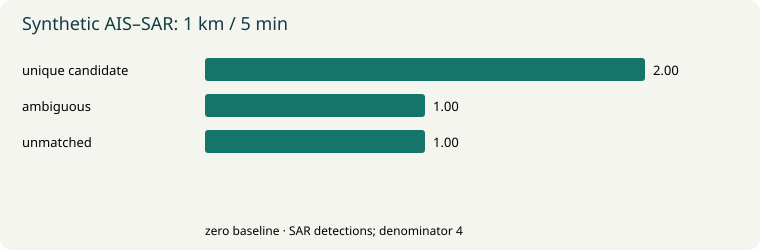

In [2]:
from math import hypot

# Invented local planar kilometres and minutes from one arbitrary origin.
detections = [('S1', 0, 0, 0), ('S2', 5, 0, 10),
              ('S3', 10, 0, 20), ('S4', 15, 0, 30)]
ais_positions = [('A', 0.6, 0, 2), ('B', 4.5, 0, 10),
                 ('C', 5.5, 0, 11), ('D', 11, 0, 25),
                 ('E', 15.2, 0, 42)]
distance_gate_km = 1.0
time_gate_min = 5

def candidate_gate(detections, positions, distance_km, time_min):
    if distance_km < 0 or time_min < 0:
        raise ValueError('Gates must be nonnegative; inputs must be complete finite numbers.')
    return {sid: [aid for aid, ax, ay, at in positions
                  if hypot(ax-sx, ay-sy) <= distance_km and abs(at-st) <= time_min]
            for sid, sx, sy, st in detections}

candidates = candidate_gate(detections, ais_positions, distance_gate_km, time_gate_min)
counts = {'unique candidate': sum(len(ids) == 1 for ids in candidates.values()),
          'ambiguous': sum(len(ids) > 1 for ids in candidates.values()),
          'unmatched': sum(len(ids) == 0 for ids in candidates.values())}
denominator = len(detections)
print('Synthetic SAR detections (id, x km, y km, minute):', detections)
print('Synthetic AIS positions (id, x km, y km, minute):', ais_positions)
print(f'Inclusive gates: distance <= {distance_gate_km:g} km AND absolute time difference <= {time_gate_min:g} min')
print('Candidate IDs by detection:', candidates)
print('Counts / all synthetic SAR detections:', counts, '/', denominator)
print('Unmatched fraction:', counts['unmatched']/denominator if denominator else 'unknown (no detections)')
print(f"Current result: {counts['unique candidate']} unique-candidate, {counts['ambiguous']} ambiguous, {counts['unmatched']} unmatched of {denominator} detections.")
print('Candidates are retained, not assigned identities. No category determines legality or deliberate AIS suppression.')
bars(counts, f'Synthetic AIS–SAR: {distance_gate_km:g} km / {time_gate_min:g} min',
     f'SAR detections; denominator {denominator}')


## Interpret the result

At the default 1 km / 5 min gates, S1 has A; S2 retains B and C; S3 has D exactly at both boundaries; S4 has none. Thus 2/4 detections have a unique candidate, 1/4 is ambiguous and 1/4 is unmatched. The printed result and SVG recompute after edits. A unique candidate is only a candidate under a rule. An unmatched detection is not proof of illegal fishing, deliberate AIS suppression, or even a correctly detected vessel. These invented four detections cannot estimate fleet prevalence; real coverage and detection denominators differ.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Set `time_gate_min = 15`, predict the candidates, then rerun: E becomes a candidate for S4, giving 3 unique-candidate, 1 ambiguous and 0 unmatched detections. Restore 5 minutes and reduce `distance_gate_km` to 0.99: boundary candidate D is excluded, giving 1 unique-candidate, 1 ambiguous and 2 unmatched. Explain why selecting the nearest candidate would hide ambiguity. Candidates may be reused across detections; this screen imposes no global assignment. State what independent identity and coverage evidence a real investigation would need.

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Nine source lessons: Ocean Watch
James L. Tobias / jltobias, *Ocean Watch: Fishing, Dark Vessels & One Health*, inspected 2026-11-01. The following are source files at the reviewed commit, not unverified reconstructed Lab launchers.

| Lesson | Evidence / purpose | Source file |
|---|---|---|
| 01 · Observed ocean | Historical 2017–2021 SAR-derived activity; coverage and denominators | [Pinned notebook](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/blob/145a73e500cb06070f399a040206802cc279174e/content/01_observed_ocean.ipynb) |
| 02 · Ocean in 3D | Observed map and a separate conceptual satellite-to-ecosystem scene | [Pinned notebook](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/blob/145a73e500cb06070f399a040206802cc279174e/content/02_ocean_in_3d.ipynb) |
| 03 · Matching and uncertainty | Synthetic AIS–SAR gates and assignments | [Pinned notebook](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/blob/145a73e500cb06070f399a040206802cc279174e/content/03_matching_and_uncertainty.ipynb) |
| 04 · SAR detection | Actual Sentinel-1 crop and a separate synthetic detector | [Pinned notebook](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/blob/145a73e500cb06070f399a040206802cc279174e/content/04_sar_detection.ipynb) |
| 05 · Satellite catalog | Saved real metadata and optional live STAC search | [Pinned notebook](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/blob/145a73e500cb06070f399a040206802cc279174e/content/05_satellite_catalog.ipynb) |
| 06 · Environment and health | NOAA analysis, separate synthetic series and confounding | [Pinned notebook](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/blob/145a73e500cb06070f399a040206802cc279174e/content/06_environment_and_health.ipynb) |
| 07 · Food and equity | Scenario accounting for retention, yield, loss and access | [Pinned notebook](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/blob/145a73e500cb06070f399a040206802cc279174e/content/07_food_and_equity.ipynb) |
| 08 · Fish stocks | Attributed FAO context and a hypothetical biomass model | [Pinned notebook](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/blob/145a73e500cb06070f399a040206802cc279174e/content/08_fish_stocks.ipynb) |
| 09 · GFW workbench | Synthetic CSV schema until a user supplies an export | [Pinned notebook](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/blob/145a73e500cb06070f399a040206802cc279174e/content/09_gfw_workbench.ipynb) |

## Connect the idea: One Health
Marine ecosystems, aquatic foods, livelihoods, labor conditions and coastal environmental exposures can interact with human, animal and ecosystem health. Use the [WHO/OHHLEP One Health definitions and principles](https://www.who.int/publications/m/item/one-health-definitions-and-principles) to ask which pathway and measurements a study needs. Vessel activity alone measures neither catch, stock abundance, dietary intake, contaminants nor disease; these fixtures support no causal health inference. Invite affected communities into framing and interpretation.

## Ocean citations, rights and use
- Paolo, F. S., Kroodsma, D., Raynor, J., et al. (2024). *Satellite mapping reveals extensive industrial activity at sea*. Nature **625**, 85–91. [Paper](https://doi.org/10.1038/s41586-023-06825-8). The 2017–2021 [analysis-data deposit](https://doi.org/10.6084/m9.figshare.24309475.v4), Paolo, Kroodsma, Davis & Hochberg (2024), version 4, is **CC BY 4.0**. It is linked context, not an input to this atlas.
- Global Fishing Watch, [apparent-fishing guidance](https://globalfishingwatch.org/dataset-and-code-fishing-activity/) and [platform terms](https://globalfishingwatch.org/terms-of-use/), inspected 2026-11-01: **CC BY-NC 4.0** for the described services; retain product-specific metadata. The deposit's CC BY license does not automatically cover new platform exports.
- NOAA NCEI, [OISST v2.1](https://www.ncei.noaa.gov/products/optimum-interpolation-sst), and [Sentinel-1 RTC / Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/dataset/sentinel-1-rtc) are source-course inputs only. Source acknowledgement: Contains modified Copernicus Sentinel data (2024), processed by Microsoft Planetary Computer. Natural Earth coastline is public domain. No pixels, coastline or temperature observations are copied here; product-specific terms apply.
- FAO (2025), *Review of the state of world marine fishery resources – 2025*, supplies source-course stock context; [assessment announcement](https://www.fao.org/newsroom/detail/fao-releases-the-most-detailed-global-assessment-of-marine-fish-stocks-to-date). [ICEYE's dark-vessel article](https://www.iceye.com/blog/dark-vessels-in-northern-europe-and-how-iceyes-satellites-find-them) motivates the commercial-SAR discussion; no vendor graphics, detections or performance claims are reproduced.

The [pinned source register](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/blob/145a73e500cb06070f399a040206802cc279174e/content/sources.md) and [methods](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/blob/145a73e500cb06070f399a040206802cc279174e/content/methods.md) retain exact queries, attribution and further provider references. Source software is MIT; source prose/figures are CC BY 4.0 where applicable. This atlas's candidate fixture, code and SVG are original, separately licensed under MIT (code) and CC BY 4.0 (prose/figures/fixtures). No institutional endorsement is implied.


## Sources, continuation and limits

**Source repository:** [JupyterLite-Global-Fishing-Watch-and-Dark-Vessels](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels).

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/blob/145a73e500cb06070f399a040206802cc279174e/README.md); inspected 2026-11-01, commit `145a73e500cb`. Repository content and linked works keep their original terms. Summaries and exercises here are newly authored.

The pinned Ocean Watch course separates historical 2017–2021 study products, actual Sentinel-1 pixels and NOAA derivatives, synthetic experiments and optional live services. This atlas copies none of those data, code, imagery or the conceptual AI cover. Source 3D views need their own graphics/runtime support; current platform exports have product-specific access and rights.

- [Read Ocean Watch](https://jltobias.github.io/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/) — Read the source course and its historical, observed and synthetic evidence distinctions. **HTTP 200 - entry only**
- [Run source Ocean Watch Lab](https://jltobias.github.io/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/lab/index.html?path=01_observed_ocean.ipynb) — Run source lesson 01; source runtimes, data rights and optional service limits apply. **HTTP 200 - entry only**
- [Explore Global Fishing Watch](https://globalfishingwatch.org/map/) — External GFW platform; product-specific access and CC BY-NC terms differ from the CC BY publication deposit. **HTTP 200 - entry only**

**Runtime budget:** this default is fewer than 100 values and normally completes within seconds; allow 60 seconds per cell while first loading Python. For native/GPU tools, use the source's local/server guide in an isolated environment, start with one small public/synthetic fixture, limit a trial to 5 minutes, and inspect memory, provider costs and outputs before scaling. For live models, use an approved authenticated backend with server-side secrets and a bounded single request; do not put credentials or sensitive records into a browser. Nothing in this chapter calls those services.

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)
